# Exploring the News Headlines Sarcasm Dataset (v2)

JSON-lines file: one record per line with `is_sarcastic`, `headline`, `article_link`. Sarcastic headlines come from *The Onion*, non-sarcastic from *HuffPost*.

In [1]:
# load Sarcasm
import re
from collections import Counter
from urllib.parse import urlparse

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 120)

df = pd.read_json("data/raw/Sarcasm_Headlines_Dataset_v2.json", lines=True)
print(df.shape)
df.head()

(28619, 3)


,is_sarcastic,headline,article_link
0,1,thirtysomething scientists unveil doomsday clock of hair loss,https://www.theonion.com/thirtysomething-scientists-unveil-doomsday-clock-of-hai-1819586205
1,0,"dem rep. totally nails why congress is falling short on gender, racial equality",https://www.huffingtonpost.com/entry/donna-edwards-inequality_us_57455f7fe4b055bb1170b207
2,0,eat your veggies: 9 deliciously different recipes,https://www.huffingtonpost.com/entry/eat-your-veggies-9-delici_b_8899742.html
3,1,inclement weather prevents liar from getting to work,https://local.theonion.com/inclement-weather-prevents-liar-from-getting-to-work-1819576031
4,1,mother comes pretty close to using word 'streaming' correctly,https://www.theonion.com/mother-comes-pretty-close-to-using-word-streaming-cor-1819575546


## Schema, missing values, duplicates

In [2]:
df.info()
print("\nnulls:\n", df.isna().sum())
print("\nempty headlines:", (df.headline.str.strip() == "").sum())
print("duplicate headlines:", df.headline.duplicated().sum())
print("duplicate links:", df.article_link.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 28619 entries, 0 to 28618
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   is_sarcastic  28619 non-null  int64
 1   headline      28619 non-null  str  
 2   article_link  28619 non-null  str  
dtypes: int64(1), str(2)
memory usage: 670.9 KB

nulls:
 is_sarcastic    0
headline        0
article_link    0
dtype: int64

empty headlines: 0
duplicate headlines: 116
duplicate links: 2


In [3]:
# Duplicate headlines: do any carry conflicting labels?
dups = df[df.headline.duplicated(keep=False)]
conflicts = dups.groupby("headline").is_sarcastic.nunique().gt(1).sum()
print(f"{dups.headline.nunique()} headlines appear more than once; {conflicts} with conflicting labels")
dups.sort_values("headline").head(10)

80 headlines appear more than once; 0 with conflicting labels


,is_sarcastic,headline,article_link
7260,1,"'no way to prevent this,' says only nation where this regularly happens",https://www.theonion.com/no-way-to-prevent-this-says-only-nation-where-this-r-1819578287
12216,1,"'no way to prevent this,' says only nation where this regularly happens",https://www.theonion.com/no-way-to-prevent-this-says-only-nation-where-this-r-1820163660
12856,1,"'no way to prevent this,' says only nation where this regularly happens",https://www.theonion.com/no-way-to-prevent-this-says-only-nation-where-this-r-1826142891
10254,1,"'no way to prevent this,' says only nation where this regularly happens",https://www.theonion.com/no-way-to-prevent-this-says-only-nation-where-this-r-1819577935
10139,1,"'no way to prevent this,' says only nation where this regularly happens",https://www.theonion.com/no-way-to-prevent-this-says-only-nation-where-this-r-1830073842
18118,1,"'no way to prevent this,' says only nation where this regularly happens",https://www.theonion.com/no-way-to-prevent-this-says-only-nation-where-this-r-1819576527
15499,1,"'no way to prevent this,' says only nation where this regularly happens",https://www.theonion.com/no-way-to-prevent-this-says-only-nation-where-this-r-1823016659
7184,1,"'no way to prevent this,' says only nation where this regularly happens",https://www.theonion.com/no-way-to-prevent-this-says-only-nation-where-this-r-1830308976
5806,1,"'no way to prevent this,' says only nation where this regularly happens",https://www.theonion.com/no-way-to-prevent-this-says-only-nation-where-this-r-1819578474
5060,1,"'no way to prevent this,' says only nation where this regularly happens",https://www.theonion.com/no-way-to-prevent-this-says-only-nation-where-this-r-1819580358


## Label balance

              count    pct
is_sarcastic              
0             14985  52.36
1             13634  47.64


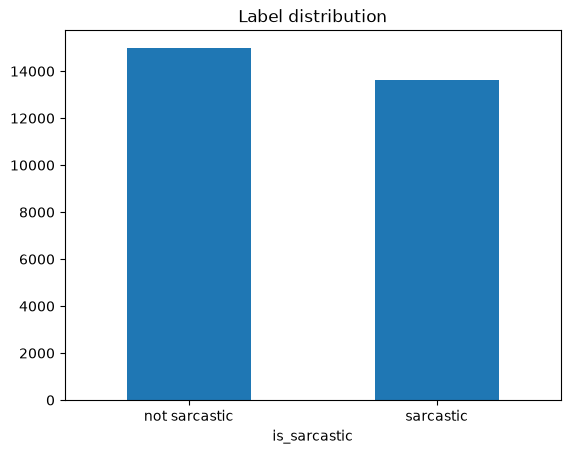

In [4]:
counts = df.is_sarcastic.value_counts().sort_index()
print(pd.DataFrame({"count": counts, "pct": (counts / len(df) * 100).round(2)}))
counts.rename({0: "not sarcastic", 1: "sarcastic"}).plot.bar(rot=0, title="Label distribution")
plt.show()

## Source domain vs. label

If the domain perfectly predicts the label, the link must never be a model input (leakage).

In [5]:
df["domain"] = df.article_link.map(lambda u: urlparse(u).netloc.replace("www.", ""))
pd.crosstab(df.domain, df.is_sarcastic, margins=True).sort_values("All", ascending=False).head(10)

is_sarcastic,0,1,All
domain,,,
All,14985,13634,28619
huffingtonpost.com,14403,0,14403
theonion.com,0,6577,6577
local.theonion.com,0,3351,3351
politics.theonion.com,0,2222,2222
entertainment.theonion.com,0,1337,1337
huffingtonpost.comhttp:,503,0,503
sports.theonion.com,0,123,123
huffingtonpost.comhttps:,79,0,79


## Headline length

In [6]:
df["n_chars"] = df.headline.str.len()
df["n_words"] = df.headline.str.split().str.len()
df.groupby("is_sarcastic")[["n_chars", "n_words"]].describe().T

is_sarcastic              0             1
n_chars count  14985.000000  13634.000000
        mean      59.558625     65.331011
        std       17.318876     23.551257
        min        7.000000      8.000000
        25%       48.000000     49.000000
        50%       61.000000     64.000000
        75%       71.000000     80.000000
        max      228.000000    926.000000
n_words count  14985.000000  13634.000000
        mean       9.815616     10.307540
        std        2.886045      3.849470
        min        2.000000      2.000000
        25%        8.000000      8.000000
        50%       10.000000     10.000000
        75%       12.000000     13.000000
        max       38.000000    151.000000

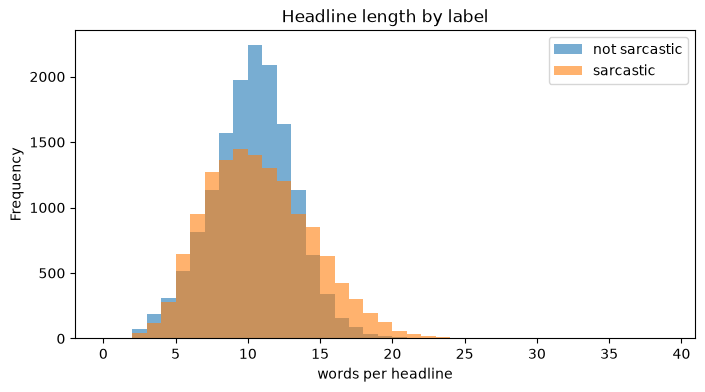

longest headlines:


,n_words,is_sarcastic,headline
7302,151,1,"hot wheels ranked number one toy for rolling down ramp, knocking over dominoes that send marble down a funnel, dropp..."
24815,39,1,"elmore leonard, modern prose master, noted for his terse prose style and for writing about things perfectly and succ..."
23598,38,0,"occasionally you realize someone you thought was a dear friend is actually a foe, their true character finally revea..."
16588,31,1,"'12 years a slave,' 'captain phillips,' 'american hustle,' 'wolf of wall street,' 'blue jasmine,' 'dallas buyers clu..."
27972,30,1,"mia farrow: 'it's possible my son was fathered by frank sinatra, mario puzo, george mcgovern, robert altman, anthony..."


In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
for label, name in [(0, "not sarcastic"), (1, "sarcastic")]:
    df.loc[df.is_sarcastic == label, "n_words"].plot.hist(bins=range(0, 40), alpha=0.6, label=name, ax=ax)
ax.set_xlabel("words per headline"); ax.legend(); ax.set_title("Headline length by label")
plt.show()
print("longest headlines:")
df.nlargest(5, "n_words")[["n_words", "is_sarcastic", "headline"]]

## Surface features: casing, punctuation, digits, quotes

In [8]:
feats = pd.DataFrame({
    "has_upper": df.headline.str.contains(r"[A-Z]"),
    "has_digit": df.headline.str.contains(r"\d"),
    "has_question": df.headline.str.contains(r"\?"),
    "has_exclaim": df.headline.str.contains("!"),
    "has_quote": df.headline.str.contains(r"[\"'‘’“”]"),
    "has_colon": df.headline.str.contains(":"),
    "non_ascii": df.headline.map(lambda s: not s.isascii()),
    "is_sarcastic": df.is_sarcastic,
})
(feats.groupby("is_sarcastic").mean() * 100).round(2).T.rename(columns={0: "% not sarc", 1: "% sarc"})

is_sarcastic,% not sarc,% sarc
has_upper,0.00,0.00
has_digit,15.02,14.30
has_question,4.84,0.73
has_exclaim,1.07,0.26
has_quote,37.86,26.51
has_colon,11.91,6.30
non_ascii,0.81,0.62


## Vocabulary: most frequent and most class-distinctive words

In [9]:
STOP = set("""a an the of to in for on and or is are was were be by with at from as it its this that
his her their our your my i you he she we they not no but so if than then into about after over up out
just new will has have had can s t""".split())

def tokens(s):
    return re.findall(r"[a-z']+", s.lower())

cnt = {lab: Counter(t for h in df.headline[df.is_sarcastic == lab] for t in tokens(h) if t not in STOP)
       for lab in (0, 1)}
pd.DataFrame({"not sarcastic": [w for w, _ in cnt[0].most_common(20)],
              "sarcastic": [w for w, _ in cnt[1].most_common(20)]})

,not sarcastic,sarcastic
0,trump,man
1,how,report
2,what,area
3,why,all
4,donald,who
5,trump's,woman
6,says,trump
7,more,year
8,who,'
9,all,one


In [10]:
# Smoothed log-odds ratio: which words lean most toward each class
import numpy as np
vocab = set(cnt[0]) | set(cnt[1])
tot0, tot1 = sum(cnt[0].values()), sum(cnt[1].values())
rows = []
for w in vocab:
    c0, c1 = cnt[0][w], cnt[1][w]
    if c0 + c1 < 30:
        continue
    rows.append((w, c0, c1, np.log((c1 + 1) / (tot1 + len(vocab))) - np.log((c0 + 1) / (tot0 + len(vocab)))))
lo = pd.DataFrame(rows, columns=["word", "n_not", "n_sarc", "log_odds_sarc"]).sort_values("log_odds_sarc")
print("vocab size:", len(vocab))
pd.concat([lo.head(15).reset_index(drop=True), lo.tail(15)[::-1].reset_index(drop=True)], axis=1,
          keys=["→ not sarcastic", "→ sarcastic"])

vocab size: 30256


→ not sarcastic                            → sarcastic               \
              word n_not n_sarc log_odds_sarc        word n_not n_sarc   
0           here's   166      1     -4.449240     fucking     0    101   
1         huffpost    58      0     -4.101931        shit     0     78   
2            trans    51      0     -3.975637     clearly     0     56   
3            queer    50      0     -3.956219        fuck     0     54   
4       kardashian    47      0     -3.895594        area    10    490   
5            lgbtq    41      0     -3.762063    realizes     0     42   
6           jenner    40      0     -3.737965   kavanaugh     0     37   
7            'snl'    34      0     -3.579741      unable     0     37   
8          roundup    32      0     -3.520901    archives     0     33   
9           trevor    30      0     -3.458381         per     0     30   
10            lgbt    49      1     -3.243269      nation     9    233   
11          donald   454     19     -3.148959       onion     1     40   
12         colbert    39      1     -3.020126   wondering     1     39   
13          tweets    64      3     -2.812486     elderly     1     37   
14     transgender    46      2     -2.775929     assures     1     35   

                  
   log_odds_sarc  
0       4.600579  
1       4.345054  
2       4.018658  
3       3.982940  
4       3.774155  
5       3.736807  
6       3.613193  
7       3.613193  
8       3.501967  
9       3.409594  
10      3.128343  
11      2.996032  
12      2.971339  
13      2.920046  
14      2.865978

## Random examples

In [11]:
for lab in (1, 0):
    print("SARCASTIC" if lab else "NOT SARCASTIC")
    for h in df[df.is_sarcastic == lab].headline.sample(8, random_state=0):
        print("  -", h)
    print()

SARCASTIC
  - man at bar has incredibly complicated reason for why he enjoys rolling rock
  - divorced parents a little hurt child's christmas list doesn't include heartbreaking wish for them to get back together
  - last civil war tortoise dies
  - first-time carjacker wasn't expecting a stick shift
  - italy, japan advance to g8 finals
  - area man to make fun of dancing for a bit before nervously joining in
  - anarchy symbol updated to appeal to today's teens
  - obesity-study lab rat's life pretty sweet

NOT SARCASTIC
  - the reclusive billionaire bankrolling ted cruz
  - mosul offensive going faster than planned, iraqi pm says
  - where in the world is the best place to be in may?
  - rare rossini and hot jazz at caramoor
  - the welcome return of black wall street
  - meet 10 inspiring people over 50 giving back to the world
  - the only way to know what neil gorsuch really thinks about gay sex is to ask him about it
  - beyonce shares photo of blue ivy and jay z for father's da